# 🎯 Entrenador Interactivo de YOLO
### YOLOv5 · YOLOv8 · YOLOv9 · YOLOv10 · YOLOv11

---
**Antes de empezar:**
1. Andá a `Entorno de ejecución` → `Cambiar tipo de entorno de ejecución`
2. Seleccioná **GPU T4** (gratis) y guardá
3. Ejecutá las celdas de arriba hacia abajo en orden ✅

> Ejecutar una celda: hacé clic en el botón ▶ a la izquierda, o `Shift + Enter`

---
## Celda 1 · Verificar GPU
Verificamos que Colab nos asignó una GPU para entrenar más rápido.

In [ ]:
import subprocess
result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
if result.returncode == 0:
    print('✅ GPU disponible:')
    # Mostrar solo la línea con el nombre de la GPU
    for line in result.stdout.split('\n'):
        if 'MiB' in line or 'GeForce' in line or 'Tesla' in line or 'T4' in line or 'A100' in line:
            print(' ', line.strip())
    print()
    print('El entrenamiento será mucho más rápido que en CPU 🚀')
else:
    print('⚠️  No se detectó GPU.')
    print('   Andá a Entorno de ejecución → Cambiar tipo de entorno → GPU T4')


✅ GPU disponible:
  |   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
  | N/A   48C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |

El entrenamiento será mucho más rápido que en CPU 🚀


---
## Celda 2 · Instalar librerías
Instalamos todo lo necesario (esto puede tardar 1-2 minutos la primera vez).

In [ ]:
print('📦 Instalando librerías...')
!pip install ultralytics roboflow -q
print()
print('✅ Todo instalado correctamente.')


📦 Instalando librerías...

✅ Todo instalado correctamente.


---
## Celda 3 · ⚙️ CONFIGURACIÓN PRINCIPAL

**Editá los valores entre comillas según tus preferencias antes de ejecutar.**

> La API key de Roboflow **no** va acá: cargala en los *Secrets* de Colab (ícono de llave 🔑, nombre `ROBOFLOW_API_KEY`). La celda 4 la lee de ahí y, si no está, la pide por teclado.

### Versiones de YOLO disponibles:
| Opción | Versión | Cuándo usarla |
|--------|---------|---------------|
| `"5"` | YOLOv5 | Clásico estable, muy testeado |
| `"8"` | YOLOv8 | Moderno y equilibrado (**RECOMENDADO**) |
| `"9"` | YOLOv9 | Alta precisión, más lento |
| `"10"` | YOLOv10 | Eficiente para producción |
| `"11"` | YOLOv11 | El más nuevo |

### Tamaños de modelo:
| Opción | Tamaño | Para qué sirve |
|--------|--------|----------------|
| `"n"` | Nano | Más rápido, menos preciso |
| `"s"` | Small | Rápido y razonablemente preciso |
| `"m"` | Medium | Equilibrado (**RECOMENDADO**) |
| `"l"` | Large | Más preciso, más lento |
| `"x"` | XLarge | Máxima precisión |

### Épocas (cuánto aprende el modelo):
| Valor | Descripción |
|-------|-------------|
| `50`  | Rápido, resultado básico |
| `100` | Equilibrado (**RECOMENDADO**) |
| `200` | Mejor resultado, más lento |
| `300` | Máximo aprendizaje |

In [ ]:
# ╔══════════════════════════════════════════════╗
# ║         EDITÁ ESTOS VALORES                  ║
# ╚══════════════════════════════════════════════╝

# Versión de YOLO: "5", "8", "9", "10" o "11"
VERSION_YOLO = "8"

# Tamaño del modelo: "n", "s", "m", "l" o "x"
TAMANIO = "m"

# Épocas (cuánto aprende): 50, 100, 200, 300...
EPOCHS = 10

# Tamaño de imagen en píxeles: 320, 416, 640, 800, 1280
IMGSZ = 224

# ──────────────────────────────────────────────
# Link de tu dataset en Roboflow
# Ejemplo: "https://app.roboflow.com/mi-workspace/mi-proyecto/1"
ROBOFLOW_LINK = "https://app.roboflow.com/ucuestudiantesproyecto-gmail-com/subdataset_v2-ucu-udelar-2026-a/4" # ejemplo: "https://app.roboflow.com/WORKSPACE/PROYECTO/VERSION"

# ══════════════════════════════════════════════
#   NO MODIFICAR DESDE AQUÍ HACIA ABAJO
# ══════════════════════════════════════════════

nombres_tamanio = {"n":"Nano","s":"Small","m":"Medium","l":"Large","x":"XLarge"}

print('=' * 50)
print('  RESUMEN DE CONFIGURACIÓN')
print('=' * 50)
print(f'  Versión YOLO     : YOLOv{VERSION_YOLO}')
print(f'  Tamaño de modelo : {nombres_tamanio.get(TAMANIO, TAMANIO)} ({TAMANIO})')
print(f'  Épocas           : {EPOCHS}')
print(f'  Tamaño de imagen : {IMGSZ}px')
print(f'  Dataset          : {ROBOFLOW_LINK}')
print('=' * 50)

# Validaciones básicas
errores = []
if VERSION_YOLO not in ["5","8","9","10","11"]:
    errores.append('VERSION_YOLO debe ser "5", "8", "9", "10" o "11"')
if TAMANIO not in ["n","s","m","l","x"]:
    errores.append('TAMANIO debe ser "n", "s", "m", "l" o "x"')
if "roboflow.com" not in ROBOFLOW_LINK:
    errores.append('ROBOFLOW_LINK no parece ser un link de Roboflow válido')

if errores:
    print()
    print('❌ HAY ERRORES EN LA CONFIGURACIÓN:')
    for e in errores:
        print(f'   • {e}')
    print()
    print('Corregí los valores y volvé a ejecutar esta celda.')
else:
    print()
    print('✅ Configuración válida. Podés pasar a la siguiente celda.')


  RESUMEN DE CONFIGURACIÓN
  Versión YOLO     : YOLOv8
  Tamaño de modelo : Medium (m)
  Épocas           : 10
  Tamaño de imagen : 224px
  Dataset          : https://app.roboflow.com/ucuestudiantesproyecto-gmail-com/subdataset_v2-ucu-udelar-2026-a/4

✅ Configuración válida. Podés pasar a la siguiente celda.


---
## Celda 4 · Descargar el dataset de Roboflow
Descargamos tu dataset usando las credenciales configuradas arriba.

In [ ]:
from roboflow import Roboflow
import os
# La API key de Roboflow NO se escribe en el notebook.
# Se busca en los Secrets de Colab (ícono de llave 🔑 a la izquierda, nombre ROBOFLOW_API_KEY)
# y, si no está, se pide por teclado.
import getpass
try:
    from google.colab import userdata
    API_KEY = userdata.get('ROBOFLOW_API_KEY')
except Exception:
    API_KEY = None
if not API_KEY:
    API_KEY = getpass.getpass('API key de Roboflow: ')


# Parsear el link de Roboflow
partes = ROBOFLOW_LINK.rstrip('/').split('/')
try:
    version_num = int(partes[-1])
    proyecto    = partes[-2]
    workspace   = partes[-3]
except (ValueError, IndexError):
    raise ValueError(
        'No se pudo parsear el link de Roboflow.\n'
        'Asegurate de que termine con el número de versión.\n'
        'Ejemplo: https://app.roboflow.com/mi-workspace/mi-proyecto/1'
    )

print(f'Workspace : {workspace}')
print(f'Proyecto  : {proyecto}')
print(f'Versión   : {version_num}')
print()
print('Descargando dataset...')

rf      = Roboflow(api_key=API_KEY.strip())
del API_KEY
project = rf.workspace(workspace).project(proyecto)
dataset = project.version(version_num).download('yolov8')

DATASET_DIR = dataset.location
DATA_YAML   = os.path.join(DATASET_DIR, 'data.yaml')

# Buscar data.yaml si no está en la raíz
if not os.path.exists(DATA_YAML):
    for root, _, files in os.walk(DATASET_DIR):
        if 'data.yaml' in files:
            DATA_YAML = os.path.join(root, 'data.yaml')
            break

print()
print(f'✅ Dataset descargado en: {DATASET_DIR}')
print(f'   Archivo de datos: {DATA_YAML}')


Workspace : ucuestudiantesproyecto-gmail-com
Proyecto  : subdataset_v2-ucu-udelar-2026-a
Versión   : 4

Descargando dataset...
loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 95.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to SUBDATASET_v2-UCU-UDELAR-2026-A-4 in yolov8:: 100%|██████████| 727/727 [00:00<00:00, 8843.05it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

✅ Dataset descargado en: /content/SUBDATASET_v2-UCU-UDELAR-2026-A-4
   Archivo de datos: /content/SUBDATASET_v2-UCU-UDELAR-2026-A-4/data.yaml


# Guardar el proceso en Google Drive

**Montar Google Drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Carpeta donde se guardará todo
DRIVE_DIR = '/content/drive/MyDrive/yolo_entrenamiento'

import os
os.makedirs(DRIVE_DIR, exist_ok=True)
print(f'✅ Drive montado. Resultados se guardarán en: {DRIVE_DIR}')

Mounted at /content/drive
✅ Drive montado. Resultados se guardarán en: /content/drive/MyDrive/yolo_entrenamiento


---
## Celda 5 · 🚀 ¡Entrenar el modelo!
Acá empieza el entrenamiento. Puede tardar desde minutos hasta horas dependiendo de:
- El tamaño de tu dataset
- El tamaño del modelo elegido
- Las épocas configuradas

> No cierres la pestaña de Colab mientras entrena.

In [ ]:
from ultralytics import YOLO

nombre_modelo_map = {
    '5':  f'yolov5{TAMANIO}.pt',
    '8':  f'yolov8{TAMANIO}.pt',
    '9':  f'yolov9{TAMANIO}.pt',
    '10': f'yolov10{TAMANIO}.pt',
    '11': f'yolo11{TAMANIO}.pt',
}
nombre_modelo = nombre_modelo_map[VERSION_YOLO]

print(f'Cargando modelo base: {nombre_modelo}')
print(f'Entrenando YOLOv{VERSION_YOLO}-{TAMANIO.upper()} por {EPOCHS} épocas...')
print()

model = YOLO(nombre_modelo)

results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    project=DRIVE_DIR,
    #project='runs/train',
    name=f'yolov{VERSION_YOLO}{TAMANIO}_colab',
    exist_ok=True,
    device=0,  # Usa la GPU de Colab
    save_period = 10,
    batch=32,  # Cambiado de 8 a 32
    conf=0.4,      # ← filtra detecciones de baja confianza durante validación
    iou=0.5,       # ← más estricto para evitar boxes superpuestos
    optimizer='Adam', # Cambiado de 'SGD' a 'Adam'
    lr0=0.0001, # Cambiado de 0.01 a 0.0001
    momentum=0.937, # Se mantiene aunque Adam no lo use directamente como SGD
    close_mosaic=20,   # desactiva mosaico recién en las últimas 20 épocas
    patience=5, # Añadido para early stopping según el paper
    weight_decay=0.0001, # Cambiado de 0.0005 a 0.0001
    degrees=12.0, # Añadido para rotación según el paper
)

SAVE_DIR = str(results.save_dir)
print()
print('=' * 50)
print('  ✅ ¡ENTRENAMIENTO COMPLETADO!')
print('=' * 50)
print(f'  Resultados guardados en: {SAVE_DIR}')
print(f'  Mejor modelo: {SAVE_DIR}/weights/best.pt')


Cargando modelo base: yolov8m.pt
Entrenando YOLOv8-M por 10 épocas...

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=0.4, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SUBDATASET_v2-UCU-UDELAR-2026-A-4/data.yaml, degrees=12.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.5, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, m

In [ ]:
# En caso de que se cierre el entorno de ejecución
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


📊 Gráfico de entrenamiento:


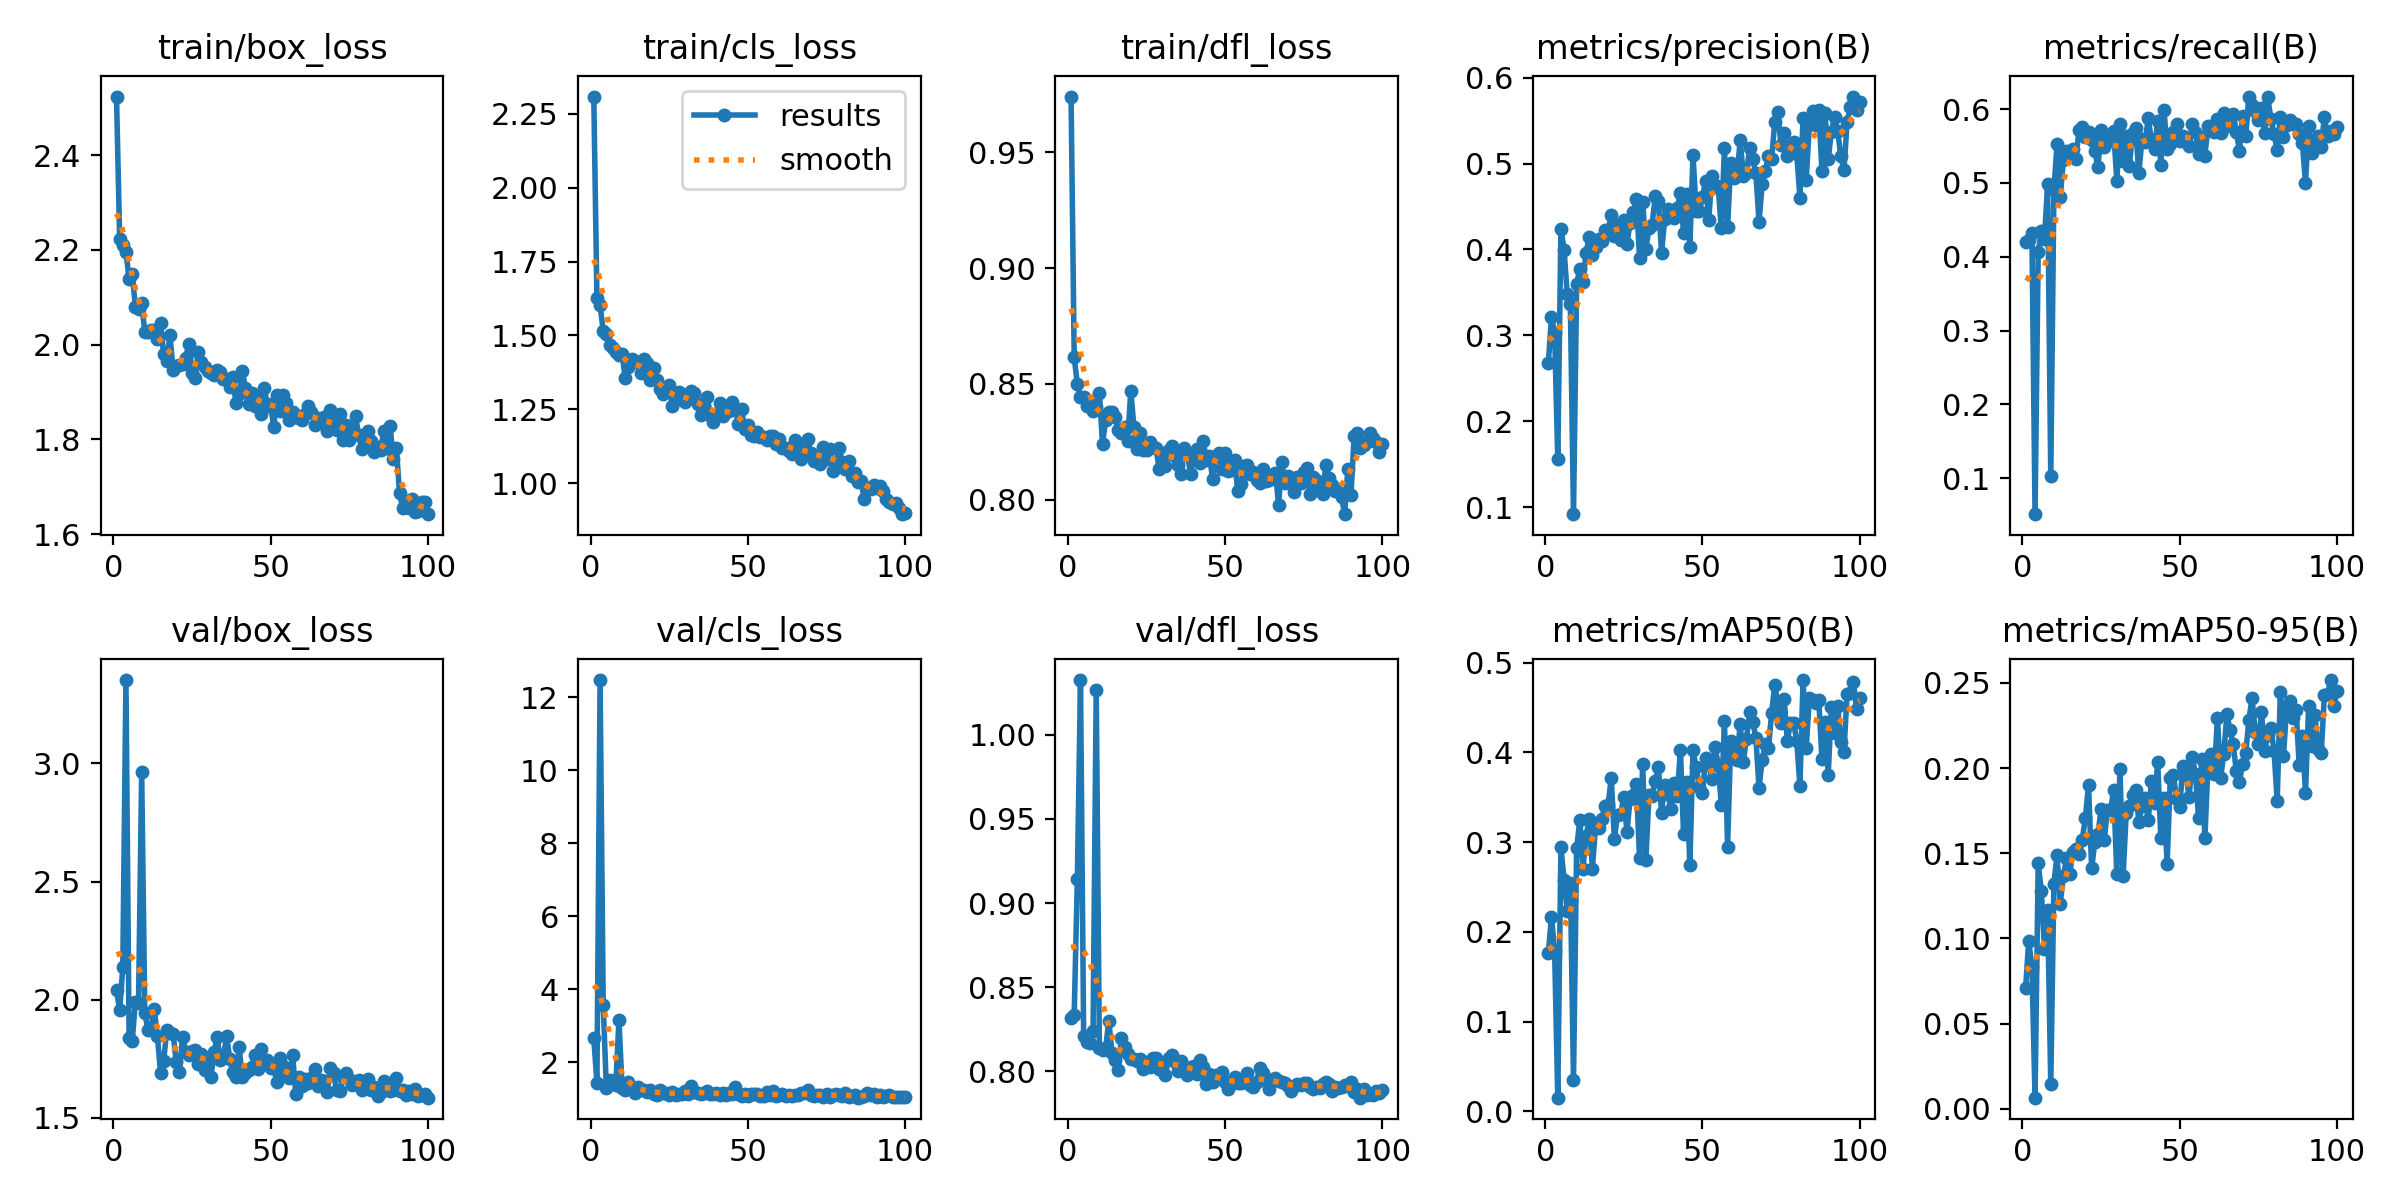


🖼️  Ejemplos de detecciones en validación:


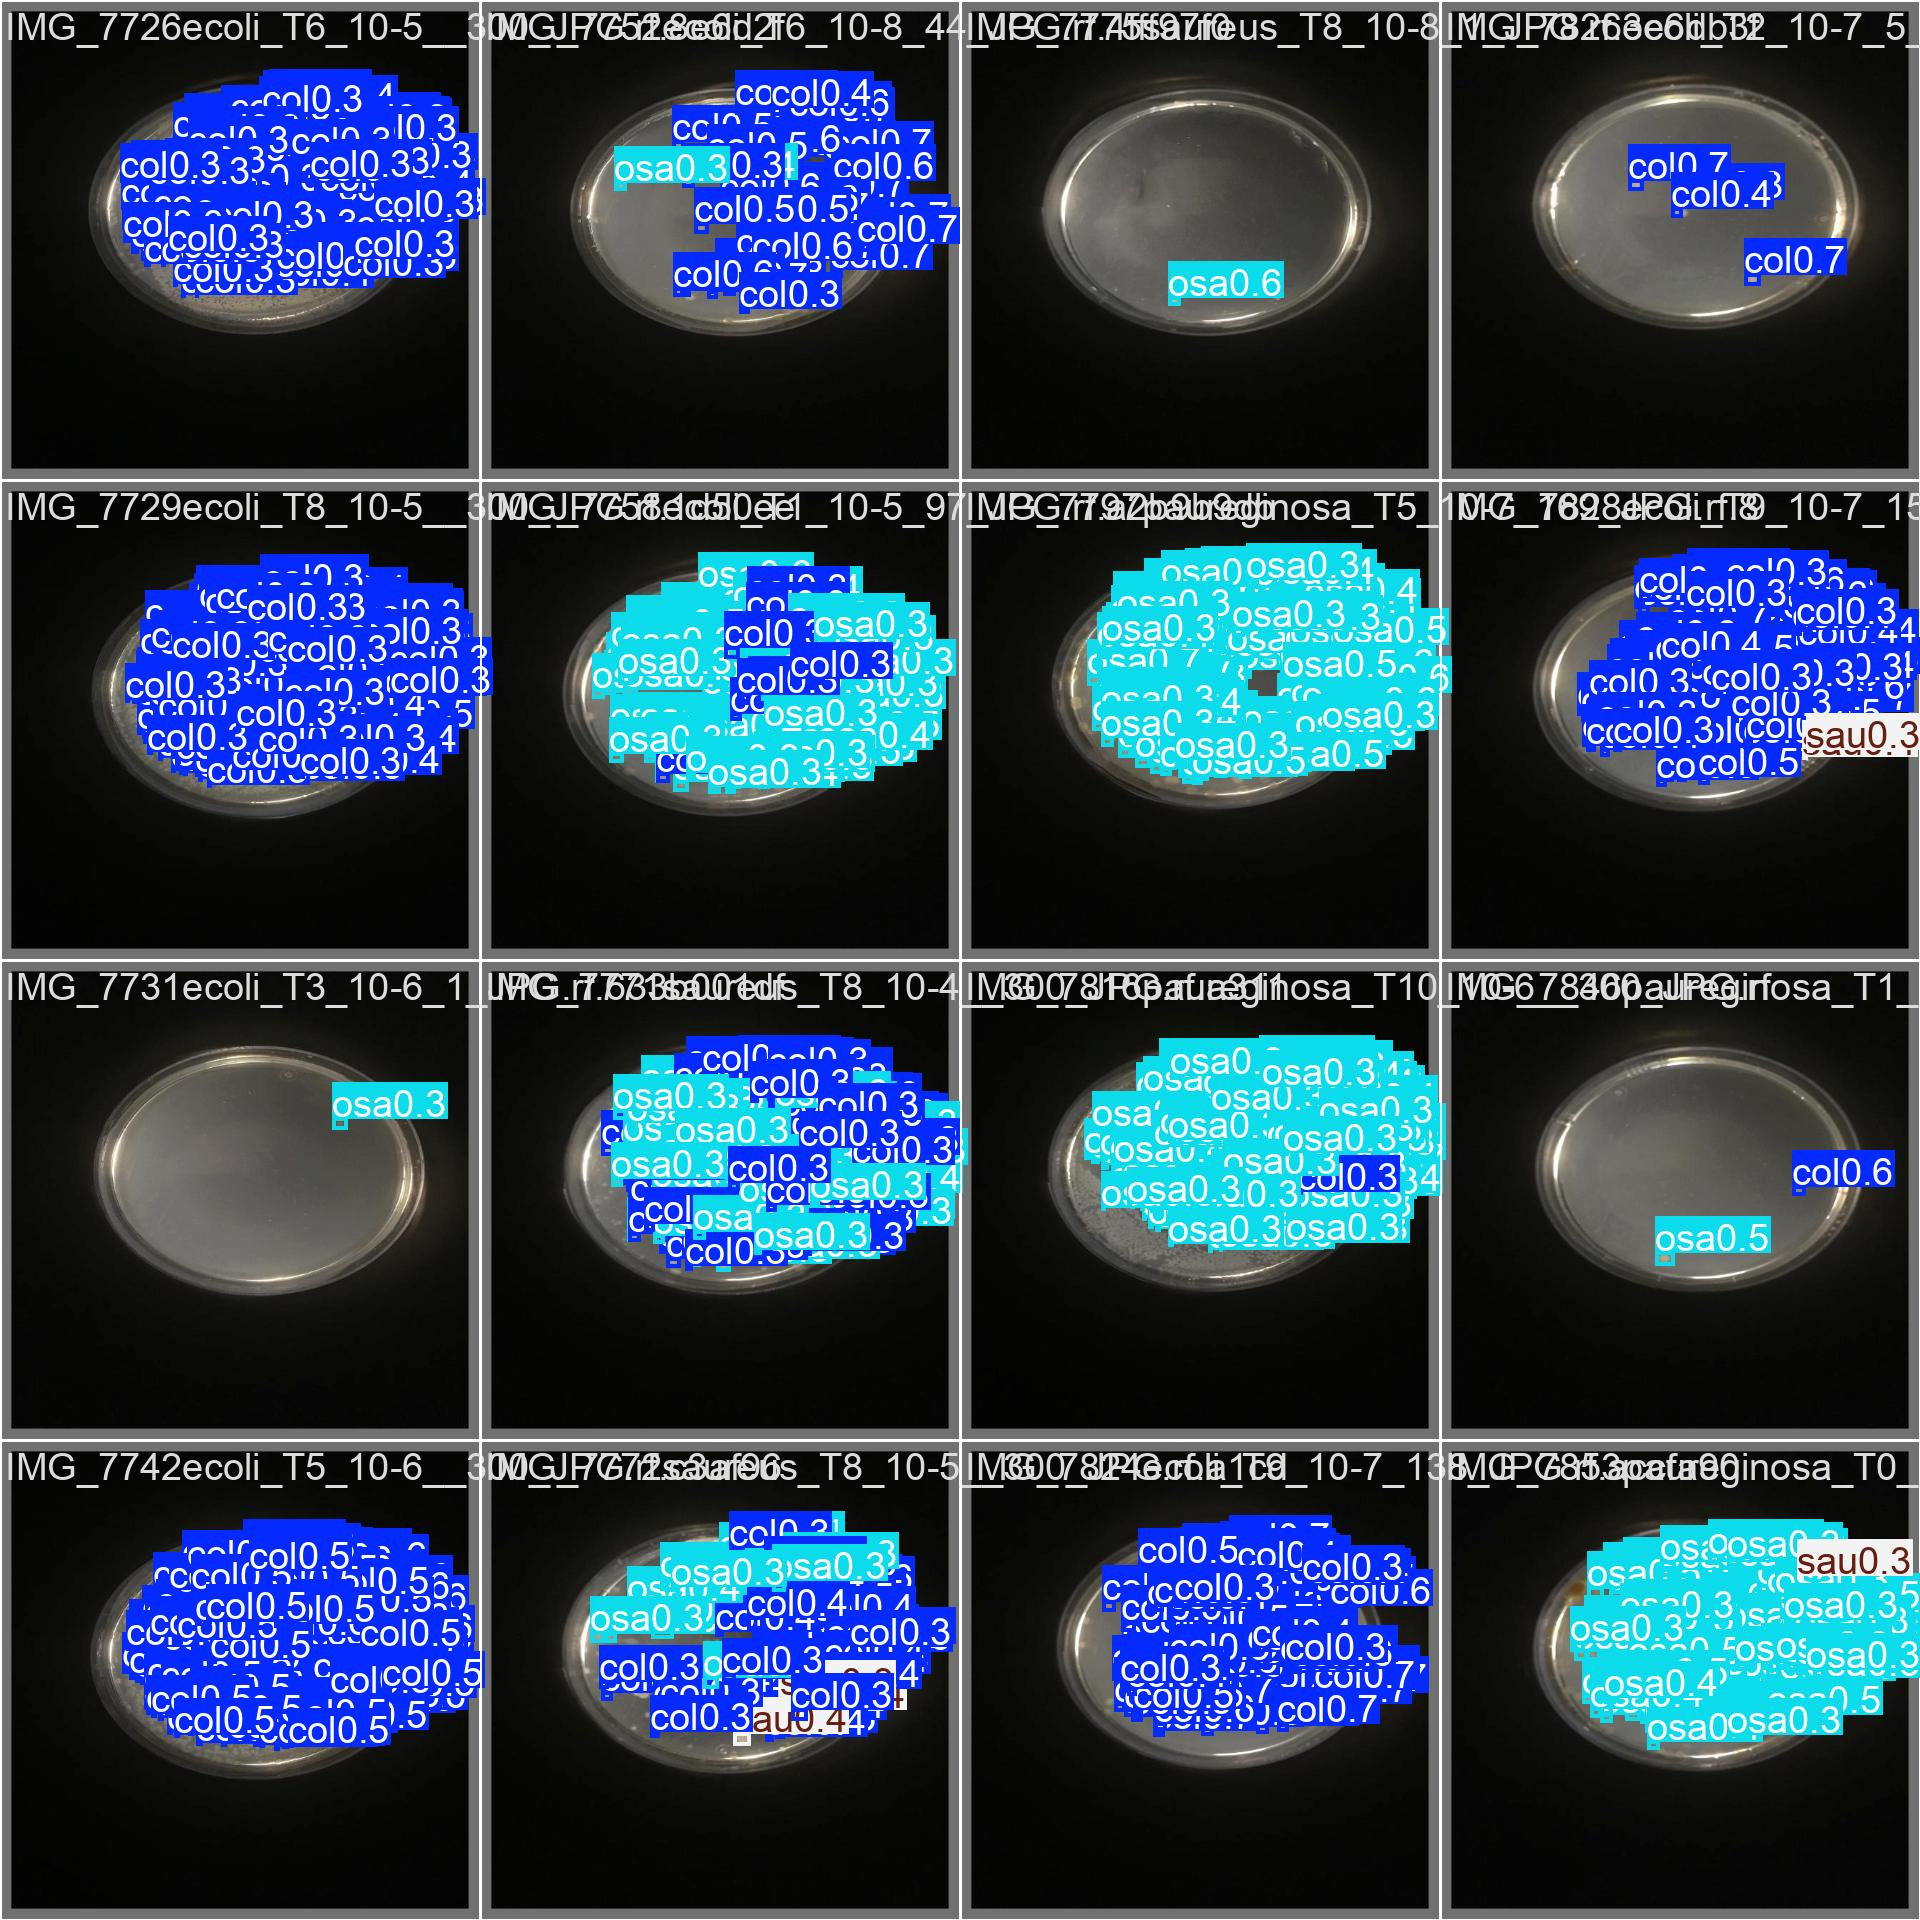

In [ ]:
#Celda 6 en caso de que se cierre el entorno de ejecucion
from IPython.display import Image, display
import os

# Definí manualmente SAVE_DIR apuntando a Drive
SAVE_DIR = '/content/drive/MyDrive/yolo_entrenamiento/yolov8m_colab'

results_png = os.path.join(SAVE_DIR, 'results.png')
if os.path.exists(results_png):
    print('📊 Gráfico de entrenamiento:')
    display(Image(filename=results_png, width=900))

val_img = os.path.join(SAVE_DIR, 'val_batch0_pred.jpg')
if os.path.exists(val_img):
    print()
    print('🖼️  Ejemplos de detecciones en validación:')
    display(Image(filename=val_img, width=700))

---
## Celda 6 · Ver resultados del entrenamiento
Mostramos las métricas y gráficos generados.

📊 Gráfico de entrenamiento:


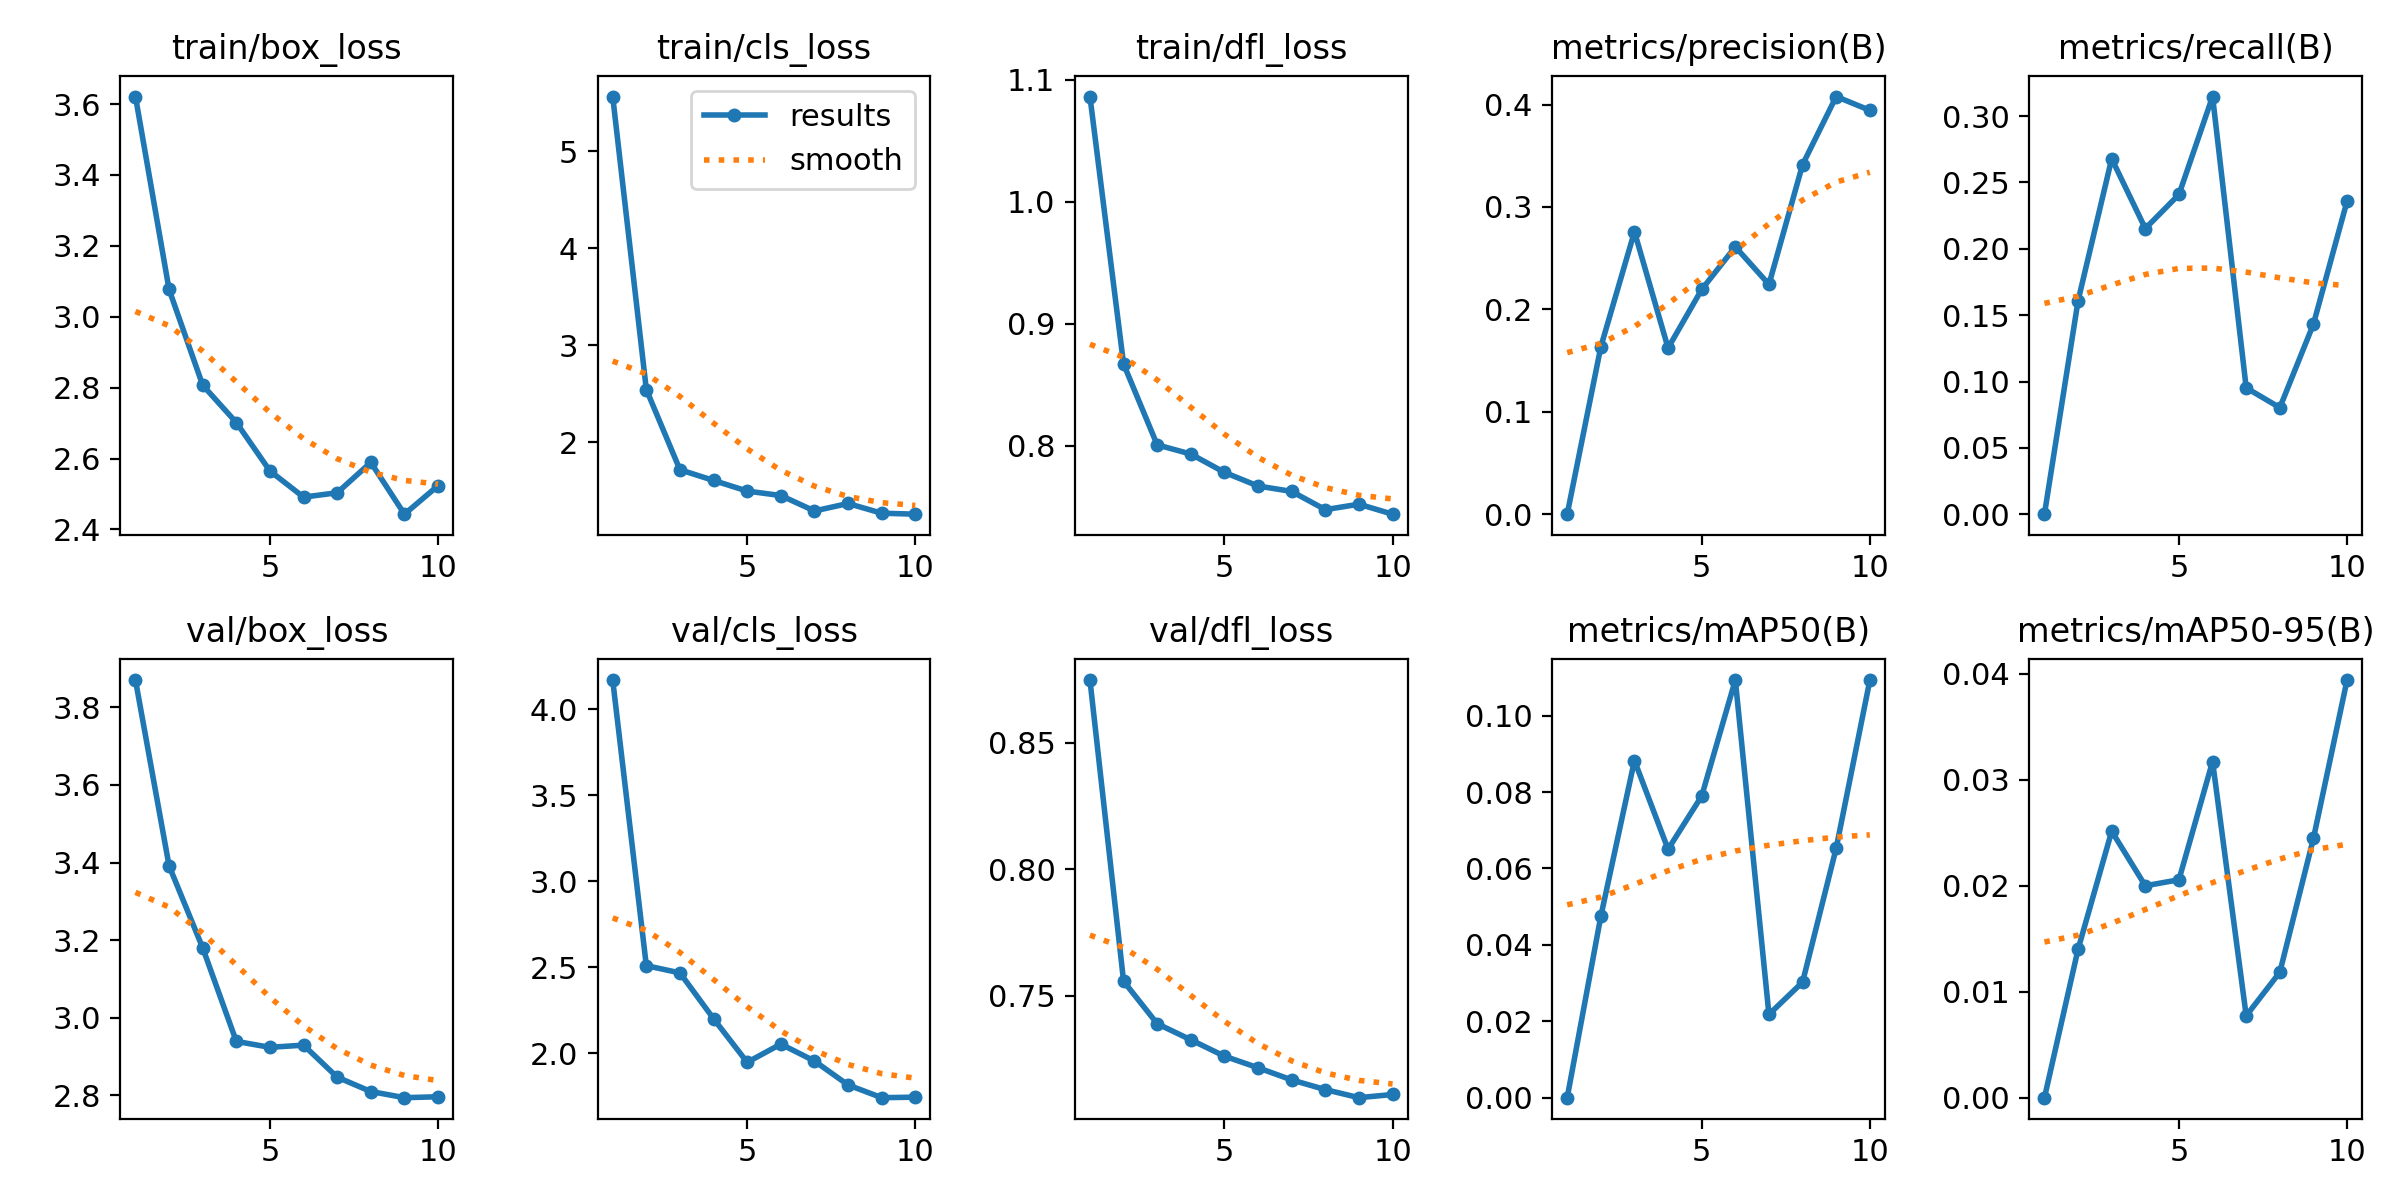


🖼️  Ejemplos de detecciones en validación:


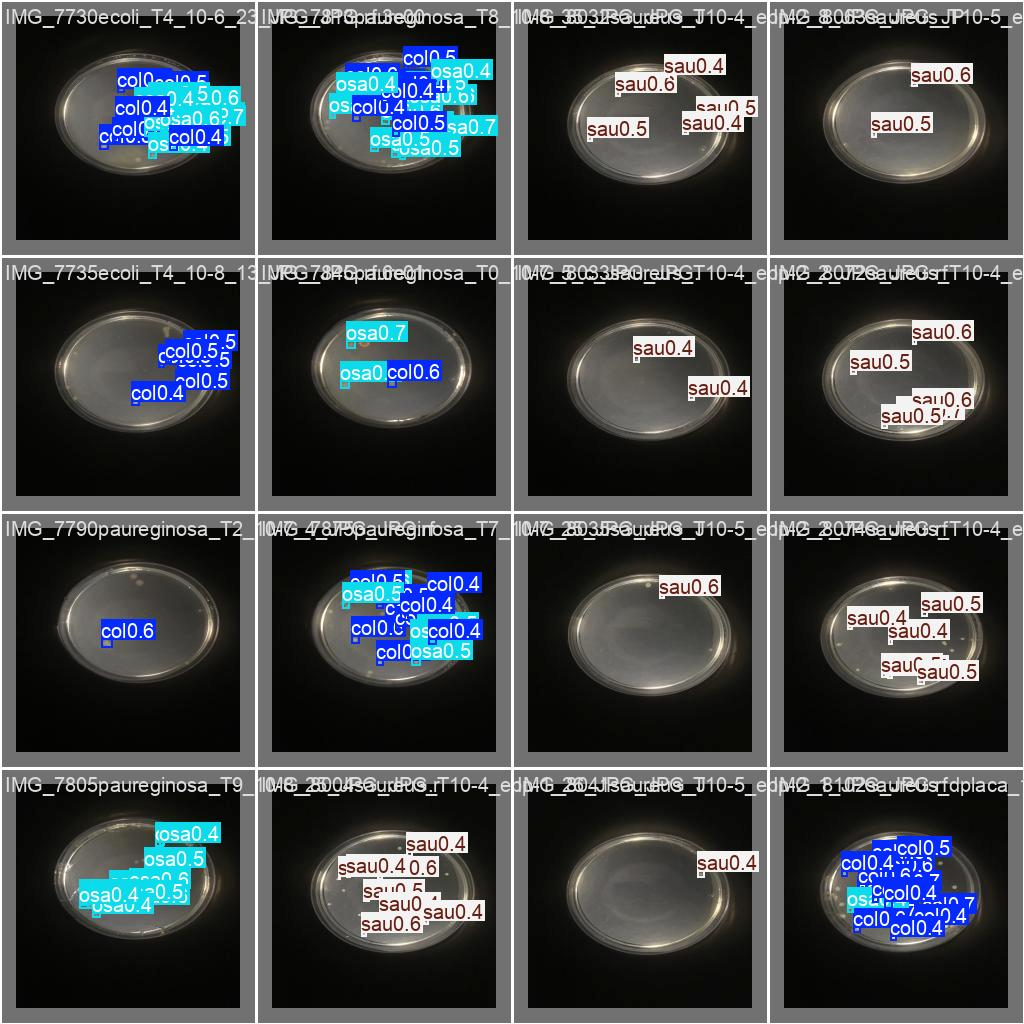

In [ ]:
from IPython.display import Image, display
import os

# Mostrar gráfico de entrenamiento
results_png = os.path.join(SAVE_DIR, 'results.png')
if os.path.exists(results_png):
    print('📊 Gráfico de entrenamiento:')
    display(Image(filename=results_png, width=900))
else:
    print('No se encontró results.png todavía.')

# Mostrar ejemplos de predicciones de validación
val_img = os.path.join(SAVE_DIR, 'val_batch0_pred.jpg')
if os.path.exists(val_img):
    print()
    print('🖼️  Ejemplos de detecciones en validación:')
    display(Image(filename=val_img, width=700))


---
## Celda 7 · Descargar el modelo entrenado
Descargá el archivo `best.pt` a tu computadora para usarlo después.

In [ ]:
from google.colab import files
import os

best_pt = os.path.join(SAVE_DIR, 'weights', 'best.pt')

if os.path.exists(best_pt):
    print(f'Descargando: {best_pt}')
    files.download(best_pt)
    print('✅ Descarga iniciada. Revisá la carpeta de descargas de tu navegador.')
else:
    print('❌ No se encontró best.pt. ¿El entrenamiento terminó correctamente?')
    print(f'   Buscando en: {best_pt}')


Descargando: /content/drive/MyDrive/yolo_entrenamiento/yolov8m_colab/weights/best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Descarga iniciada. Revisá la carpeta de descargas de tu navegador.


---
## Celda 8 (OPCIONAL) · Probar el modelo con una imagen
Podés probar tu modelo con cualquier imagen antes de descargarlo.

In [ ]:
from google.colab import files as colab_files
from ultralytics import YOLO
from IPython.display import Image as IPImage, display
import os

print('Subí una imagen para probar el modelo...')
uploaded = colab_files.upload()

if uploaded:
    imagen_path = list(uploaded.keys())[0]
    print(f'Imagen subida: {imagen_path}')
    print('Ejecutando detección...')

    model_test = YOLO(os.path.join(SAVE_DIR, 'weights', 'best.pt'))
    resultados = model_test.predict(imagen_path, conf=0.5, iou=0.45, save=True, project='predicciones', name='test')

    # Mostrar resultado
    for r in resultados:
        if r.save_dir:
            pred_path = os.path.join(r.save_dir, os.path.basename(imagen_path))
            if os.path.exists(pred_path):
                print()
                print(f'Objetos detectados: {len(r.boxes)}')
                display(IPImage(filename=pred_path, width=700))
else:
    print('No subiste ninguna imagen.')


Subí una imagen para probar el modelo...


Saving IMG_7986saureus_14.JPG to IMG_7986saureus_14.JPG
Imagen subida: IMG_7986saureus_14.JPG
Ejecutando detección...

image 1/1 /content/IMG_7986saureus_14.JPG: 224x192 7 cols, 15.2ms
Speed: 1.5ms preprocess, 15.2ms inference, 1.8ms postprocess per image at shape (1, 3, 224, 192)
Results saved to /content/runs/detect/predicciones/test


---
## ¿Qué hago ahora con el modelo descargado?

Con el archivo `best.pt` podés:

```python
from ultralytics import YOLO

# Cargar el modelo entrenado
model = YOLO('best.pt')

# Detectar objetos en una imagen
results = model('mi_foto.jpg')
results[0].show()  # Ver los resultados
```

O para detección en tiempo real con la cámara:
```python
model.predict(source=0, show=True)  # 0 = cámara web
```

# Adicional - Gráficos
Gráficos adicionales sobre los resultados del modelo

In [ ]:
from google.colab import files
import os

# Lista de archivos adicionales para descargar
additional_files = [
    'confusion_matrix.png',
    'F1_curve.png',
    'P_curve.png',
    'R_curve.png',
    'PR_curve.png',
    'labels.jpg'
]

print('Descargando archivos adicionales:')
for filename in additional_files:
    filepath = os.path.join(SAVE_DIR, filename)
    if os.path.exists(filepath):
        print(f'Descargando: {filename}')
        files.download(filepath)
        print(f'OK: Descarga de {filename} iniciada.')
    else:
        print(f'ERROR: No se encontró {filename}.')
print('\nTodas las descargas han sido iniciadas. Revisa la carpeta de descargas de tu navegador.')

Descargando archivos adicionales:
Descargando: confusion_matrix.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

OK: Descarga de confusion_matrix.png iniciada.
ERROR: No se encontró F1_curve.png.
ERROR: No se encontró P_curve.png.
ERROR: No se encontró R_curve.png.
ERROR: No se encontró PR_curve.png.
Descargando: labels.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

OK: Descarga de labels.jpg iniciada.

Todas las descargas han sido iniciadas. Revisa la carpeta de descargas de tu navegador.
